# Vital Signs Distribution Analysis: Sepsis vs Non-Sepsis Patients

This notebook visualizes the distributions of key vital signs comparing sepsis and non-sepsis patients from the **PhysioNet 2019 Sepsis Challenge** dataset.

## Vital Signs Analyzed:
- **HR** - Heart Rate (bpm)
- **MAP** - Mean Arterial Pressure (mmHg)
- **O2Sat** - Oxygen Saturation (%)
- **SBP** - Systolic Blood Pressure (mmHg)
- **Resp** - Respiratory Rate (breaths/min)
- **Temp** - Temperature (°C)
- **SpO2_FiO2** - SpO2/FiO2 Ratio (SOFA respiratory component)

## Lab Values (SOFA Components):
- **Bilirubin_direct** - Direct Bilirubin (mg/dL) - Hepatic function
- **Creatinine** - Creatinine (mg/dL) - Renal function
- **Platelets** - Platelet count (×10³/µL) - Coagulation

In [48]:
# Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

In [49]:
# ==========================================
# Configuration
# ==========================================
DATA_PATH = "./training_setA"  # Update this path if needed
VITALS = ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp', 'Temp', 'SpO2_FiO2', 'Bilirubin_direct', 'Creatinine', 'Platelets']
VITAL_NAMES = {
    'HR': 'Heart Rate (bpm)',
    'MAP': 'Mean Arterial Pressure (mmHg)',
    'O2Sat': 'Oxygen Saturation (%)',
    'SBP': 'Systolic Blood Pressure (mmHg)',
    'Resp': 'Respiratory Rate (breaths/min)',
    'Temp': 'Temperature (°C)',
    'SpO2_FiO2': 'SpO2/FiO2 Ratio',
    'Bilirubin_direct': 'Direct Bilirubin (mg/dL)',
    'Creatinine': 'Creatinine (mg/dL)',
    'Platelets': 'Platelets (×10³/µL)'
}
MAX_FILES = 20018  # Limit for faster processing

# Verify data path exists
if os.path.exists(DATA_PATH):
    print(f"✓ Data path found: {DATA_PATH}")
    print(f"  Files available: {len([f for f in os.listdir(DATA_PATH) if f.endswith('.psv')])}")
else:
    print(f"✗ Data path not found: {DATA_PATH}")
    print("  Please update DATA_PATH above.")

✓ Data path found: ./training_setA
  Files available: 20018


## 1. Data Loading Functions

In [50]:
def load_sepsis_data(data_path, max_files=MAX_FILES):
    """
    Load patient data and separate into sepsis vs non-sepsis groups.
    Returns two DataFrames: one for sepsis patients, one for non-sepsis.
    """
    files = sorted([f for f in os.listdir(data_path) if f.endswith('.psv')])[:max_files]
    
    sepsis_data = []
    non_sepsis_data = []
    
    sepsis_count = 0
    non_sepsis_count = 0
    
    # Base vitals to load from file (including lab values)
    base_vitals = ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp', 'Temp', 'FiO2', 'Bilirubin_direct', 'Creatinine', 'Platelets']
    
    print(f"Loading {len(files)} patient files...")
    
    for i, f in enumerate(files):
        if (i + 1) % 500 == 0:
            print(f"  Processed {i + 1}/{len(files)} files...")
        
        df = pd.read_csv(os.path.join(data_path, f), sep='|')
        
        # Check if patient developed sepsis (SepsisLabel column)
        if 'SepsisLabel' in df.columns:
            has_sepsis = df['SepsisLabel'].max() == 1
        else:
            continue
        
        # Calculate SpO2/FiO2 ratio
        if 'FiO2' in df.columns and 'O2Sat' in df.columns:
            fio2 = df['FiO2'].copy()
            fio2 = fio2.where(fio2 > 0, np.nan)
            # If FiO2 > 1, assume percentage and convert
            fio2 = fio2.where(fio2 <= 1, fio2 / 100)
            # Default to room air (0.21) if missing
            fio2 = fio2.fillna(0.21)
            df['SpO2_FiO2'] = df['O2Sat'] / fio2
        else:
            df['SpO2_FiO2'] = np.nan
        
        # Extract vitals (take mean per patient)
        vitals_to_extract = ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp', 'Temp', 'SpO2_FiO2', 'Bilirubin_direct', 'Creatinine', 'Platelets']
        # Only include columns that exist
        available_vitals = [v for v in vitals_to_extract if v in df.columns]
        patient_vitals = df[available_vitals].mean().to_dict()
        
        # Add missing vitals as NaN
        for v in vitals_to_extract:
            if v not in patient_vitals:
                patient_vitals[v] = np.nan
        
        patient_vitals['PatientID'] = f
        
        if has_sepsis:
            sepsis_data.append(patient_vitals)
            sepsis_count += 1
        else:
            non_sepsis_data.append(patient_vitals)
            non_sepsis_count += 1
    
    print(f"\n✓ Loaded {sepsis_count} sepsis patients and {non_sepsis_count} non-sepsis patients")
    
    sepsis_df = pd.DataFrame(sepsis_data)
    non_sepsis_df = pd.DataFrame(non_sepsis_data)
    
    return sepsis_df, non_sepsis_df


def load_all_timepoints(data_path, max_files=MAX_FILES):
    """
    Load ALL timepoints (not just means) for detailed distribution analysis.
    """
    files = sorted([f for f in os.listdir(data_path) if f.endswith('.psv')])[:max_files]
    
    all_data = []
    
    print(f"Loading all timepoints from {len(files)} patient files...")
    
    for i, f in enumerate(files):
        if (i + 1) % 500 == 0:
            print(f"  Processed {i + 1}/{len(files)} files...")
        
        df = pd.read_csv(os.path.join(data_path, f), sep='|')
        
        if 'SepsisLabel' not in df.columns:
            continue
        
        # Calculate SpO2/FiO2 ratio
        if 'FiO2' in df.columns and 'O2Sat' in df.columns:
            fio2 = df['FiO2'].copy()
            fio2 = fio2.where(fio2 > 0, np.nan)
            fio2 = fio2.where(fio2 <= 1, fio2 / 100)
            fio2 = fio2.fillna(0.21)
            df['SpO2_FiO2'] = df['O2Sat'] / fio2
        else:
            df['SpO2_FiO2'] = np.nan
        
        # Add missing columns as NaN
        for v in VITALS:
            if v not in df.columns:
                df[v] = np.nan
        
        has_sepsis = df['SepsisLabel'].max() == 1
        df['PatientID'] = f
        df['SepsisPatient'] = 'Sepsis' if has_sepsis else 'Non-Sepsis'
        
        all_data.append(df[VITALS + ['SepsisPatient', 'PatientID']])
    
    combined_df = pd.concat(all_data, ignore_index=True)
    print(f"\n✓ Total timepoints loaded: {len(combined_df):,}")
    
    return combined_df

## 2. Load Patient-Level Data

In [51]:
# Load patient-level data (mean vitals per patient)
sepsis_df, non_sepsis_df = load_sepsis_data(DATA_PATH)

Loading 20018 patient files...
  Processed 500/20018 files...
  Processed 500/20018 files...
  Processed 1000/20018 files...
  Processed 1000/20018 files...
  Processed 1500/20018 files...
  Processed 1500/20018 files...
  Processed 2000/20018 files...
  Processed 2000/20018 files...
  Processed 2500/20018 files...
  Processed 2500/20018 files...
  Processed 3000/20018 files...
  Processed 3000/20018 files...
  Processed 3500/20018 files...
  Processed 3500/20018 files...
  Processed 4000/20018 files...
  Processed 4000/20018 files...
  Processed 4500/20018 files...
  Processed 4500/20018 files...
  Processed 5000/20018 files...
  Processed 5000/20018 files...
  Processed 5500/20018 files...
  Processed 5500/20018 files...
  Processed 6000/20018 files...
  Processed 6000/20018 files...
  Processed 6500/20018 files...
  Processed 6500/20018 files...
  Processed 7000/20018 files...
  Processed 7000/20018 files...
  Processed 7500/20018 files...
  Processed 7500/20018 files...
  Processed

## 3. Statistical Summary

In [52]:
def print_statistics(sepsis_df, non_sepsis_df):
    """
    Print statistical summary comparing sepsis vs non-sepsis.
    """
    print("=" * 70)
    print("STATISTICAL SUMMARY: Sepsis vs Non-Sepsis (Patient-Level Means)")
    print("=" * 70)
    
    results = []
    
    for vital in VITALS:
        sepsis_vals = sepsis_df[vital].dropna()
        non_sepsis_vals = non_sepsis_df[vital].dropna()
        
        diff = sepsis_vals.mean() - non_sepsis_vals.mean()
        pct_diff = (diff / non_sepsis_vals.mean()) * 100
        
        results.append({
            'Vital': vital,
            'Non-Sepsis Mean': non_sepsis_vals.mean(),
            'Sepsis Mean': sepsis_vals.mean(),
            'Difference': diff,
            '% Diff': pct_diff,
            'Non-Sepsis Std': non_sepsis_vals.std(),
            'Sepsis Std': sepsis_vals.std()
        })
    
    results_df = pd.DataFrame(results)
    return results_df

# Display statistics
stats_df = print_statistics(sepsis_df, non_sepsis_df)
stats_df.round(2)

STATISTICAL SUMMARY: Sepsis vs Non-Sepsis (Patient-Level Means)


,Vital,Non-Sepsis Mean,Sepsis Mean,Difference,% Diff,Non-Sepsis Std,Sepsis Std
0,HR,84.14,89.01,4.88,5.80,13.98,15.82
1,MAP,78.51,78.04,-0.47,-0.60,10.77,10.82
2,O2Sat,97.19,97.35,0.16,0.17,2.26,2.03
3,SBP,120.33,119.49,-0.84,-0.70,16.40,16.87
4,Resp,18.45,20.07,1.62,8.78,3.55,4.34
5,Temp,36.90,37.06,0.16,0.42,0.54,0.73
6,SpO2_FiO2,429.33,397.51,-31.82,-7.41,43.55,49.46
7,Bilirubin_direct,2.36,4.08,1.72,73.10,3.86,6.30
8,Creatinine,1.27,1.57,0.30,23.58,1.40,1.62
9,Platelets,211.78,213.91,2.13,1.01,104.18,118.23


## 4. Histogram Distribution Comparison

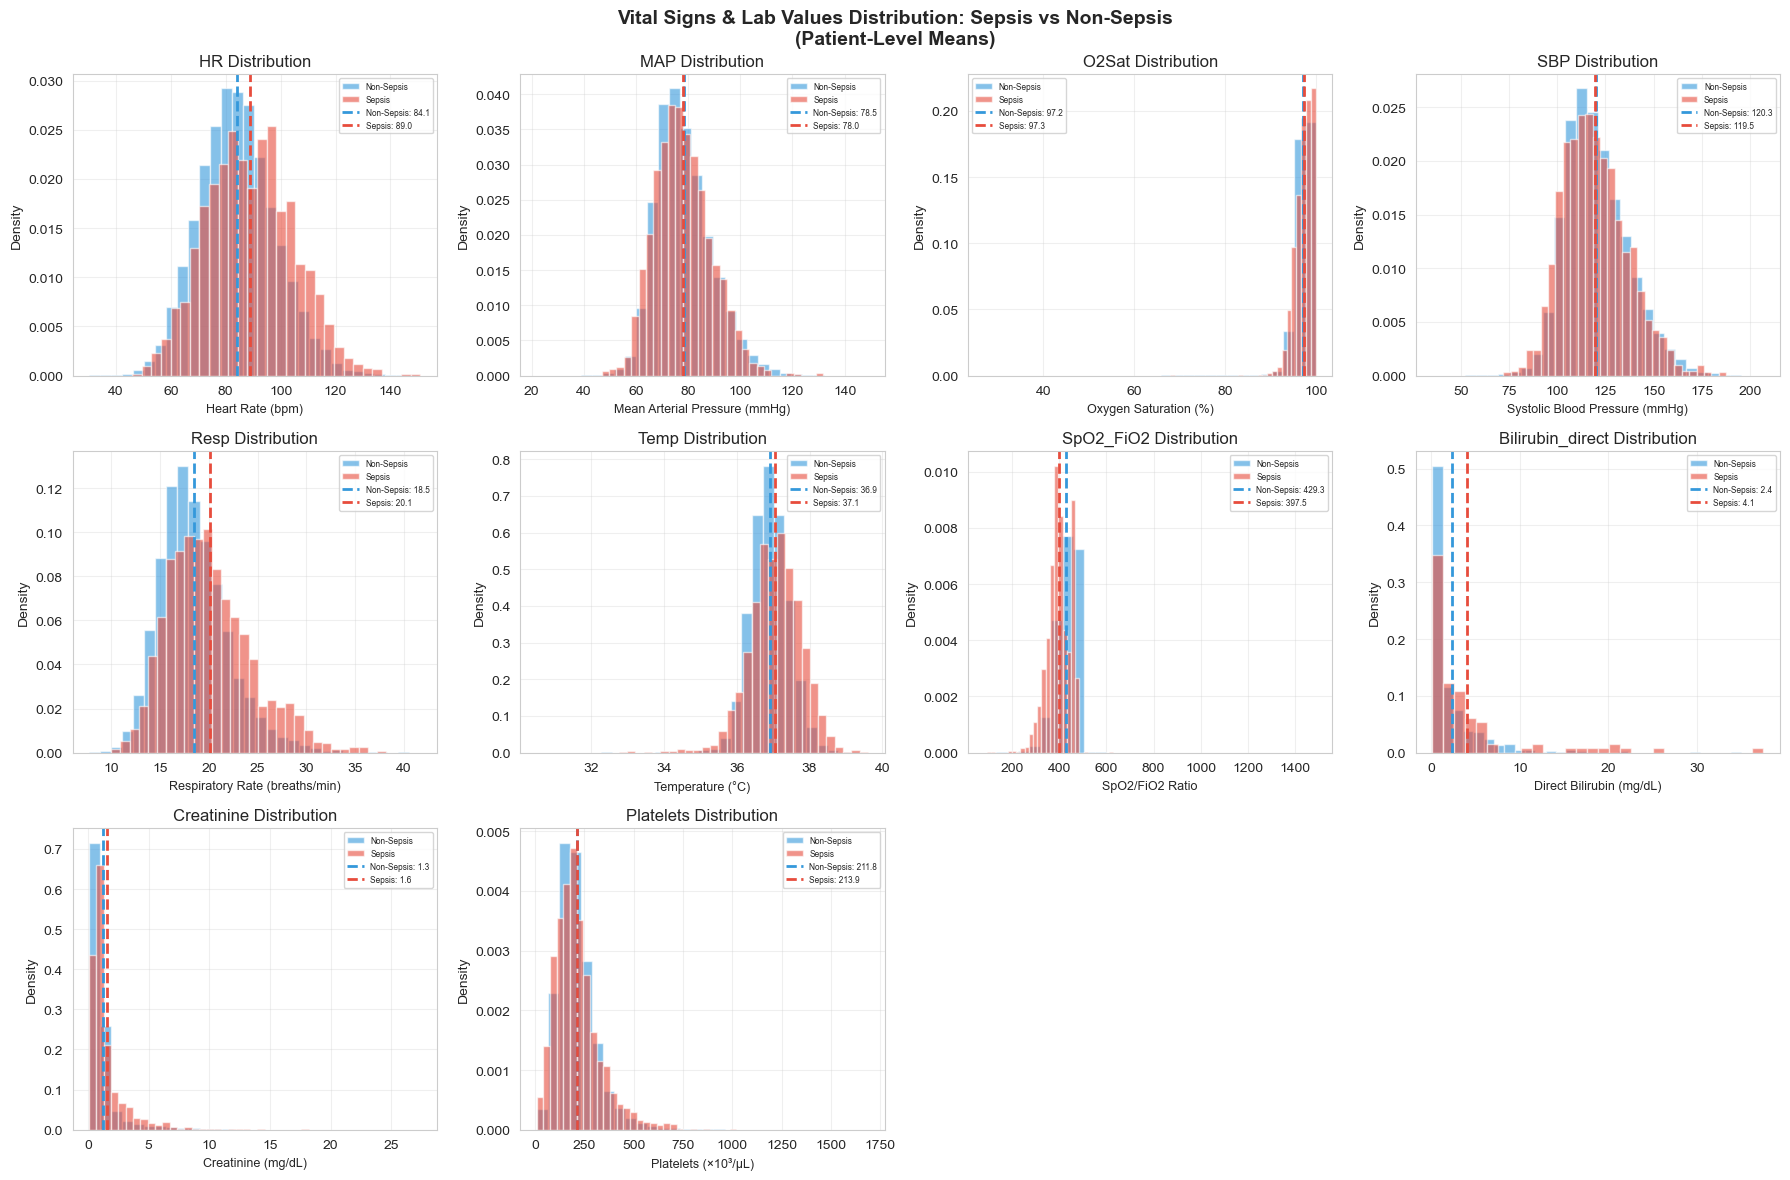

In [53]:
def plot_distribution_comparison(sepsis_df, non_sepsis_df):
    """
    Create side-by-side histogram comparisons for each vital sign.
    """
    n_vitals = len(VITALS)
    n_cols = 4
    n_rows = (n_vitals + n_cols - 1) // n_cols  # Ceiling division
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()
    
    colors = {'Sepsis': '#e74c3c', 'Non-Sepsis': '#3498db'}
    
    for idx, vital in enumerate(VITALS):
        ax = axes[idx]
        
        sepsis_vals = sepsis_df[vital].dropna()
        non_sepsis_vals = non_sepsis_df[vital].dropna()
        
        if len(sepsis_vals) == 0 or len(non_sepsis_vals) == 0:
            ax.text(0.5, 0.5, f'No data for {vital}', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(vital)
            continue
        
        ax.hist(non_sepsis_vals, bins=30, alpha=0.6, label='Non-Sepsis', 
                color=colors['Non-Sepsis'], density=True, edgecolor='white')
        ax.hist(sepsis_vals, bins=30, alpha=0.6, label='Sepsis', 
                color=colors['Sepsis'], density=True, edgecolor='white')
        
        ax.axvline(non_sepsis_vals.mean(), color=colors['Non-Sepsis'], 
                   linestyle='--', linewidth=2, label=f'Non-Sepsis: {non_sepsis_vals.mean():.1f}')
        ax.axvline(sepsis_vals.mean(), color=colors['Sepsis'], 
                   linestyle='--', linewidth=2, label=f'Sepsis: {sepsis_vals.mean():.1f}')
        
        ax.set_xlabel(VITAL_NAMES[vital], fontsize=9)
        ax.set_ylabel('Density')
        ax.set_title(f'{vital} Distribution')
        ax.legend(fontsize=6)
        ax.grid(True, alpha=0.3)
    
    # Hide unused subplots
    for idx in range(len(VITALS), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Vital Signs & Lab Values Distribution: Sepsis vs Non-Sepsis\n(Patient-Level Means)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Plot histograms
plot_distribution_comparison(sepsis_df, non_sepsis_df)

## 5. Load All Timepoints for Detailed Analysis

In [54]:
# Load all timepoints (this gives us more data points for smoother distributions)
combined_df = load_all_timepoints(DATA_PATH)

Loading all timepoints from 20018 patient files...
  Processed 500/20018 files...
  Processed 500/20018 files...
  Processed 1000/20018 files...
  Processed 1000/20018 files...
  Processed 1500/20018 files...
  Processed 1500/20018 files...
  Processed 2000/20018 files...
  Processed 2000/20018 files...
  Processed 2500/20018 files...
  Processed 2500/20018 files...
  Processed 3000/20018 files...
  Processed 3000/20018 files...
  Processed 3500/20018 files...
  Processed 3500/20018 files...
  Processed 4000/20018 files...
  Processed 4000/20018 files...
  Processed 4500/20018 files...
  Processed 4500/20018 files...
  Processed 5000/20018 files...
  Processed 5000/20018 files...
  Processed 5500/20018 files...
  Processed 5500/20018 files...
  Processed 6000/20018 files...
  Processed 6000/20018 files...
  Processed 6500/20018 files...
  Processed 6500/20018 files...
  Processed 7000/20018 files...
  Processed 7000/20018 files...
  Processed 7500/20018 files...
  Processed 7500/20018 

MISSING VALUES ANALYSIS

Total timepoints in dataset: 777,931

--------------------------------------------------------------------------------
Vital                     Missing        Valid    Missing % Data Quality   
--------------------------------------------------------------------------------
Bilirubin_direct          776,761        1,170        99.8% 🔴 Sparse       
Platelets                 727,176       50,755        93.5% 🔴 Sparse       
Creatinine                726,266       51,665        93.4% 🔴 Sparse       
Temp                      514,928      263,003        66.2% 🔴 Sparse       
SBP                       118,345      659,586        15.2% 🟡 Good         
O2Sat                      93,488      684,443        12.0% 🟡 Good         
SpO2_FiO2                  93,488      684,443        12.0% 🟡 Good         
MAP                        79,447      698,484        10.2% 🟡 Good         
Resp                       76,040      701,891         9.8% ✅ Excellent    
HR             

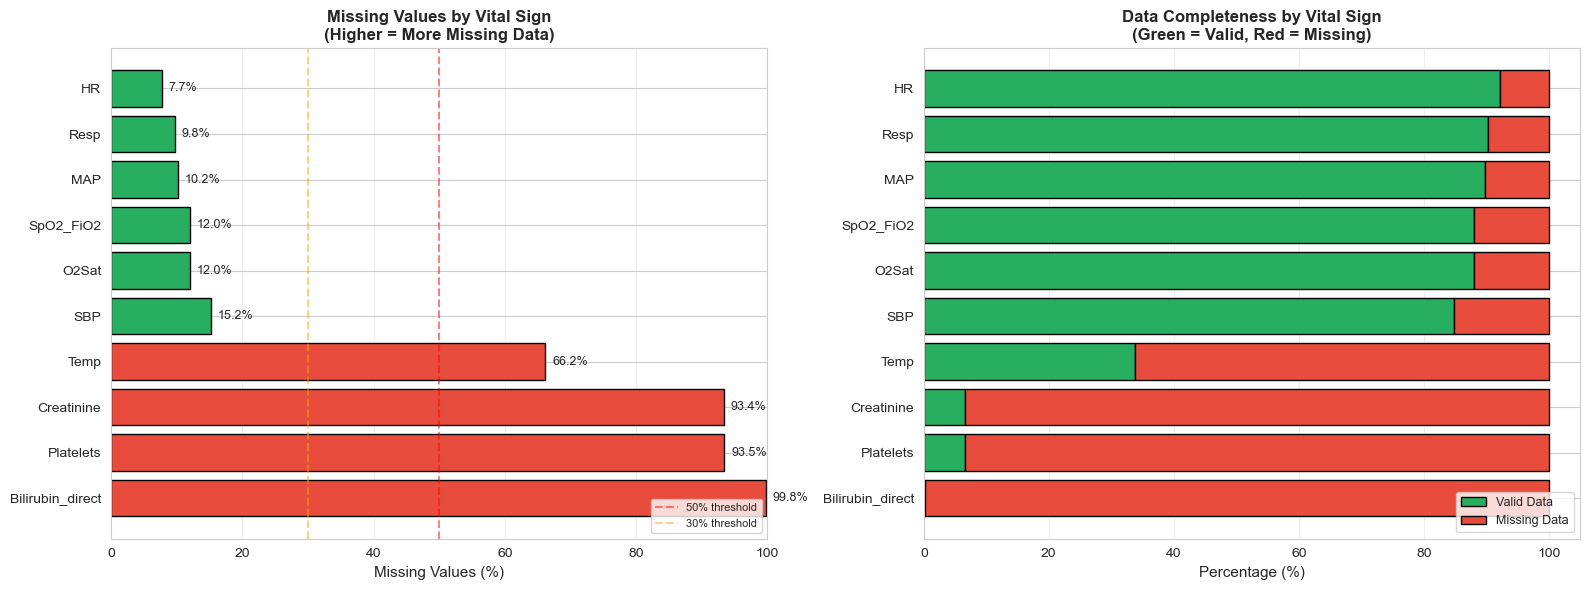


📊 KEY INSIGHTS:
----------------------------------------
• Most sparse:  Bilirubin_direct (99.8% missing)
• Most complete: HR (7.7% missing)

⚠️  Sparse vitals (>50% missing): Bilirubin_direct, Platelets, Creatinine, Temp
   → These are typically LAB VALUES measured infrequently

✅ Good data quality (<30% missing): SBP, O2Sat, SpO2_FiO2, MAP, Resp, HR
   → These are typically CONTINUOUS MONITORING vitals


In [59]:
# ==========================================
# Missing Values Analysis
# ==========================================
def analyze_missing_values(combined_df):
    """
    Analyze and visualize missing values for each vital sign.
    """
    total_rows = len(combined_df)
    
    # Calculate missing values
    missing_data = []
    for vital in VITALS:
        missing_count = combined_df[vital].isna().sum()
        missing_pct = (missing_count / total_rows) * 100
        valid_count = total_rows - missing_count
        
        missing_data.append({
            'Vital': vital,
            'Name': VITAL_NAMES[vital],
            'Missing': missing_count,
            'Valid': valid_count,
            'Missing %': missing_pct,
            'Valid %': 100 - missing_pct
        })
    
    missing_df = pd.DataFrame(missing_data)
    missing_df = missing_df.sort_values('Missing %', ascending=False)
    
    # Print summary table
    print("=" * 80)
    print("MISSING VALUES ANALYSIS")
    print("=" * 80)
    print(f"\nTotal timepoints in dataset: {total_rows:,}")
    print("\n" + "-" * 80)
    print(f"{'Vital':<20} {'Missing':>12} {'Valid':>12} {'Missing %':>12} {'Data Quality':<15}")
    print("-" * 80)
    
    for _, row in missing_df.iterrows():
        # Color-coded quality assessment
        if row['Missing %'] < 10:
            quality = "✅ Excellent"
        elif row['Missing %'] < 30:
            quality = "🟡 Good"
        elif row['Missing %'] < 60:
            quality = "🟠 Moderate"
        else:
            quality = "🔴 Sparse"
        
        print(f"{row['Vital']:<20} {row['Missing']:>12,} {row['Valid']:>12,} {row['Missing %']:>11.1f}% {quality:<15}")
    
    print("-" * 80)
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Bar chart - Missing values percentage
    ax1 = axes[0]
    colors = ['#e74c3c' if pct > 50 else '#f39c12' if pct > 30 else '#27ae60' 
              for pct in missing_df['Missing %']]
    bars = ax1.barh(missing_df['Vital'], missing_df['Missing %'], color=colors, edgecolor='black')
    ax1.set_xlabel('Missing Values (%)', fontsize=11)
    ax1.set_title('Missing Values by Vital Sign\n(Higher = More Missing Data)', fontsize=12, fontweight='bold')
    ax1.set_xlim(0, 100)
    ax1.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')
    ax1.axvline(x=30, color='orange', linestyle='--', alpha=0.5, label='30% threshold')
    ax1.legend(loc='lower right', fontsize=8)
    ax1.grid(True, alpha=0.3, axis='x')
    
    # Add percentage labels on bars
    for bar, pct in zip(bars, missing_df['Missing %']):
        ax1.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
                 f'{pct:.1f}%', va='center', fontsize=9)
    
    # Stacked bar chart - Valid vs Missing
    ax2 = axes[1]
    vitals_ordered = missing_df['Vital'].tolist()
    valid_pcts = missing_df['Valid %'].tolist()
    missing_pcts = missing_df['Missing %'].tolist()
    
    ax2.barh(vitals_ordered, valid_pcts, color='#27ae60', label='Valid Data', edgecolor='black')
    ax2.barh(vitals_ordered, missing_pcts, left=valid_pcts, color='#e74c3c', label='Missing Data', edgecolor='black')
    ax2.set_xlabel('Percentage (%)', fontsize=11)
    ax2.set_title('Data Completeness by Vital Sign\n(Green = Valid, Red = Missing)', fontsize=12, fontweight='bold')
    ax2.legend(loc='lower right', fontsize=9)
    ax2.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()
    
    # Key insights
    print("\n📊 KEY INSIGHTS:")
    print("-" * 40)
    
    # Find vitals with most/least missing
    most_missing = missing_df.iloc[0]
    least_missing = missing_df.iloc[-1]
    
    print(f"• Most sparse:  {most_missing['Vital']} ({most_missing['Missing %']:.1f}% missing)")
    print(f"• Most complete: {least_missing['Vital']} ({least_missing['Missing %']:.1f}% missing)")
    
    # Categorize by sparsity
    sparse_vitals = missing_df[missing_df['Missing %'] > 50]['Vital'].tolist()
    moderate_vitals = missing_df[(missing_df['Missing %'] > 30) & (missing_df['Missing %'] <= 50)]['Vital'].tolist()
    good_vitals = missing_df[missing_df['Missing %'] <= 30]['Vital'].tolist()
    
    if sparse_vitals:
        print(f"\n⚠️  Sparse vitals (>50% missing): {', '.join(sparse_vitals)}")
        print("   → These are typically LAB VALUES measured infrequently")
    
    if moderate_vitals:
        print(f"\n🟡 Moderate sparsity (30-50% missing): {', '.join(moderate_vitals)}")
    
    if good_vitals:
        print(f"\n✅ Good data quality (<30% missing): {', '.join(good_vitals)}")
        print("   → These are typically CONTINUOUS MONITORING vitals")
    
    return missing_df

# Run missing values analysis
missing_values_df = analyze_missing_values(combined_df)

## 6. Violin Plot Comparison

/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2823559966.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2823559966.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2823559966.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/

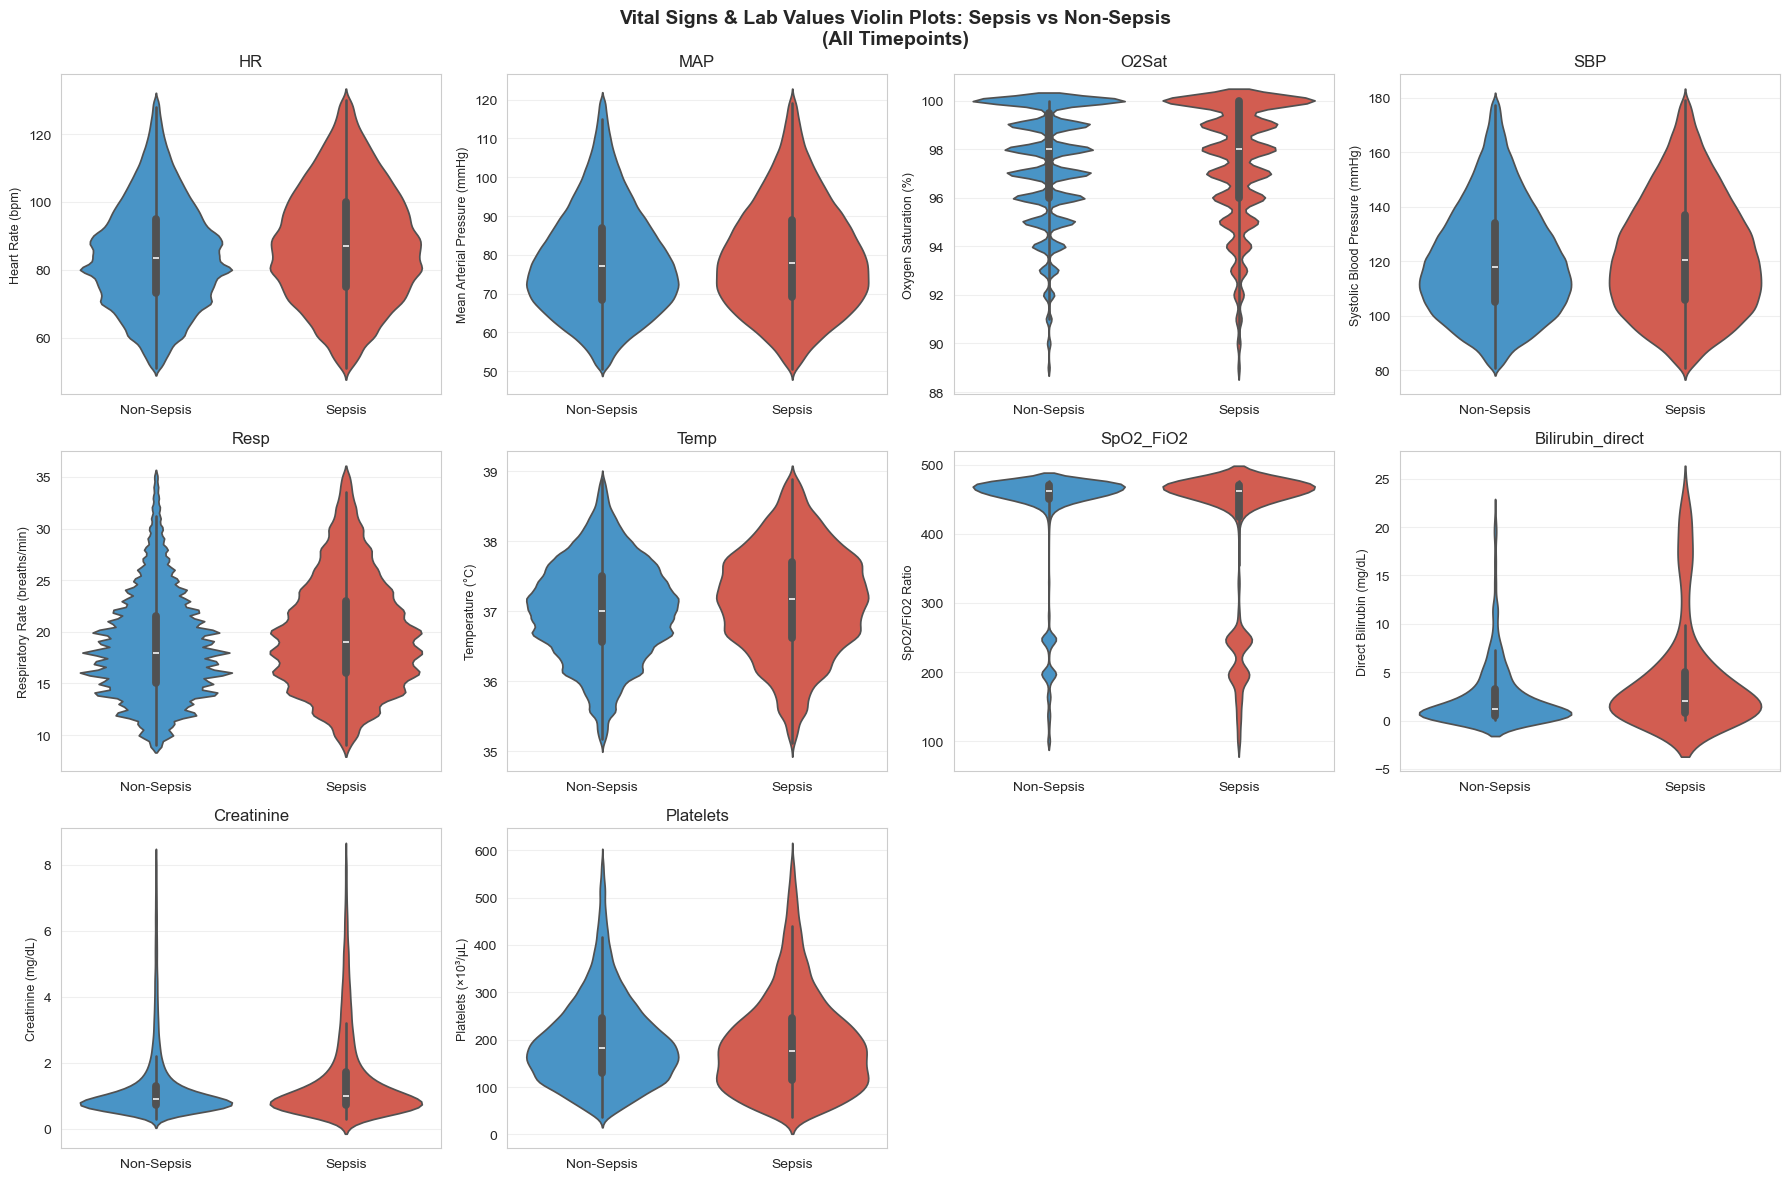

In [55]:
def plot_violin_comparison(combined_df):
    """
    Create violin plots comparing sepsis vs non-sepsis for each vital.
    """
    n_vitals = len(VITALS)
    n_cols = 4
    n_rows = (n_vitals + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()
    
    colors = {'Sepsis': '#e74c3c', 'Non-Sepsis': '#3498db'}
    palette = [colors['Non-Sepsis'], colors['Sepsis']]
    
    for idx, vital in enumerate(VITALS):
        ax = axes[idx]
        
        data = combined_df[[vital, 'SepsisPatient']].dropna()
        if len(data) == 0:
            ax.text(0.5, 0.5, f'No data for {vital}', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(vital)
            continue
            
        q1, q99 = data[vital].quantile([0.01, 0.99])
        data = data[(data[vital] >= q1) & (data[vital] <= q99)]
        
        sns.violinplot(data=data, x='SepsisPatient', y=vital, ax=ax, 
                       palette=palette, order=['Non-Sepsis', 'Sepsis'])
        
        ax.set_xlabel('')
        ax.set_ylabel(VITAL_NAMES[vital], fontsize=9)
        ax.set_title(vital)
        ax.grid(True, alpha=0.3, axis='y')
    
    # Hide unused subplots
    for idx in range(len(VITALS), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Vital Signs & Lab Values Violin Plots: Sepsis vs Non-Sepsis\n(All Timepoints)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Plot violin plots
plot_violin_comparison(combined_df)

## 7. Box Plot Comparison

/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2023551277.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2023551277.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/pm/2n62h2gn3jjgqdzwnjtg8scm0000gn/T/ipykernel_44880/2023551277.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='SepsisPatient', y=vital, ax=ax,
/var/folders/pm/2n62h2

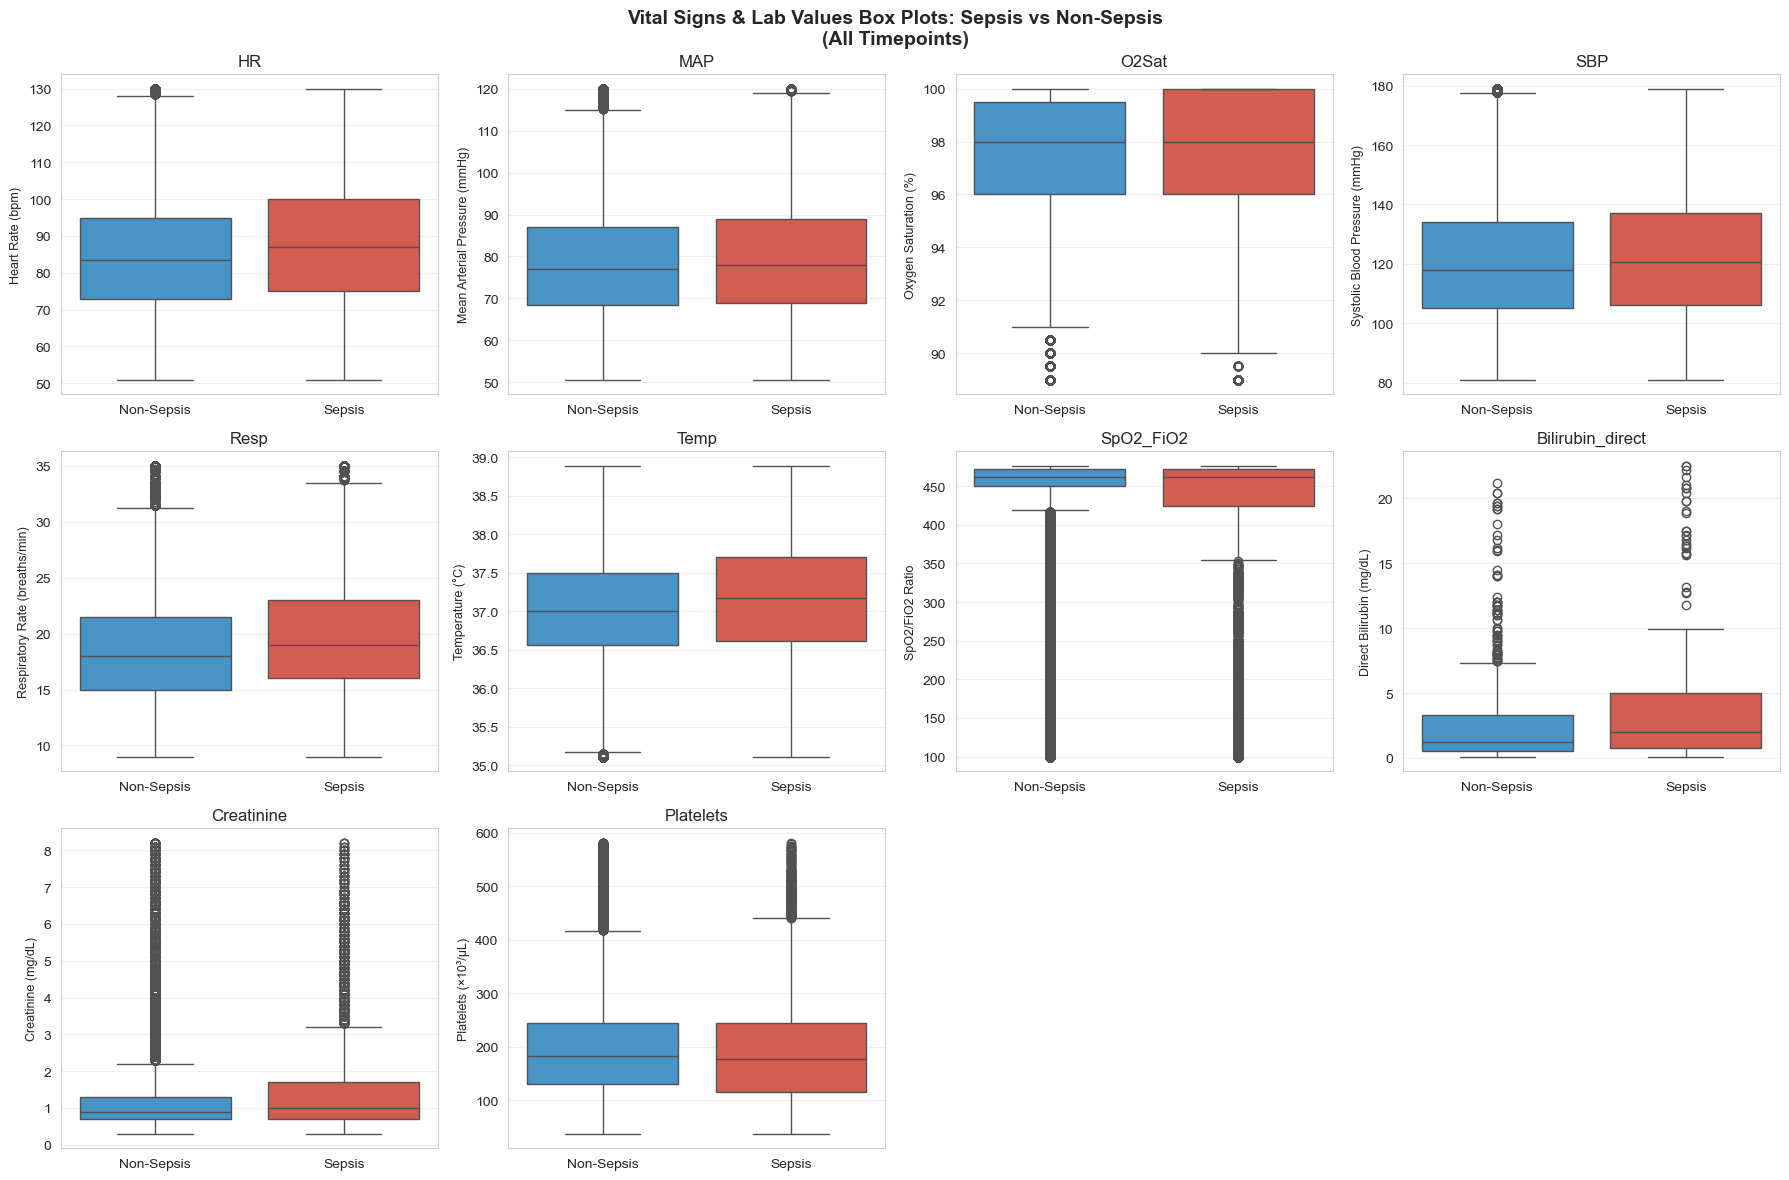

In [56]:
def plot_boxplot_comparison(combined_df):
    """
    Create box plots for quick statistical comparison.
    """
    n_vitals = len(VITALS)
    n_cols = 4
    n_rows = (n_vitals + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()
    
    colors = {'Sepsis': '#e74c3c', 'Non-Sepsis': '#3498db'}
    palette = [colors['Non-Sepsis'], colors['Sepsis']]
    
    for idx, vital in enumerate(VITALS):
        ax = axes[idx]
        
        data = combined_df[[vital, 'SepsisPatient']].dropna()
        if len(data) == 0:
            ax.text(0.5, 0.5, f'No data for {vital}', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(vital)
            continue
            
        q1, q99 = data[vital].quantile([0.01, 0.99])
        data = data[(data[vital] >= q1) & (data[vital] <= q99)]
        
        sns.boxplot(data=data, x='SepsisPatient', y=vital, ax=ax,
                    palette=palette, order=['Non-Sepsis', 'Sepsis'])
        
        ax.set_xlabel('')
        ax.set_ylabel(VITAL_NAMES[vital], fontsize=9)
        ax.set_title(vital)
        ax.grid(True, alpha=0.3, axis='y')
    
    # Hide unused subplots
    for idx in range(len(VITALS), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Vital Signs & Lab Values Box Plots: Sepsis vs Non-Sepsis\n(All Timepoints)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Plot box plots
plot_boxplot_comparison(combined_df)

## 8. KDE (Kernel Density) Plot Comparison

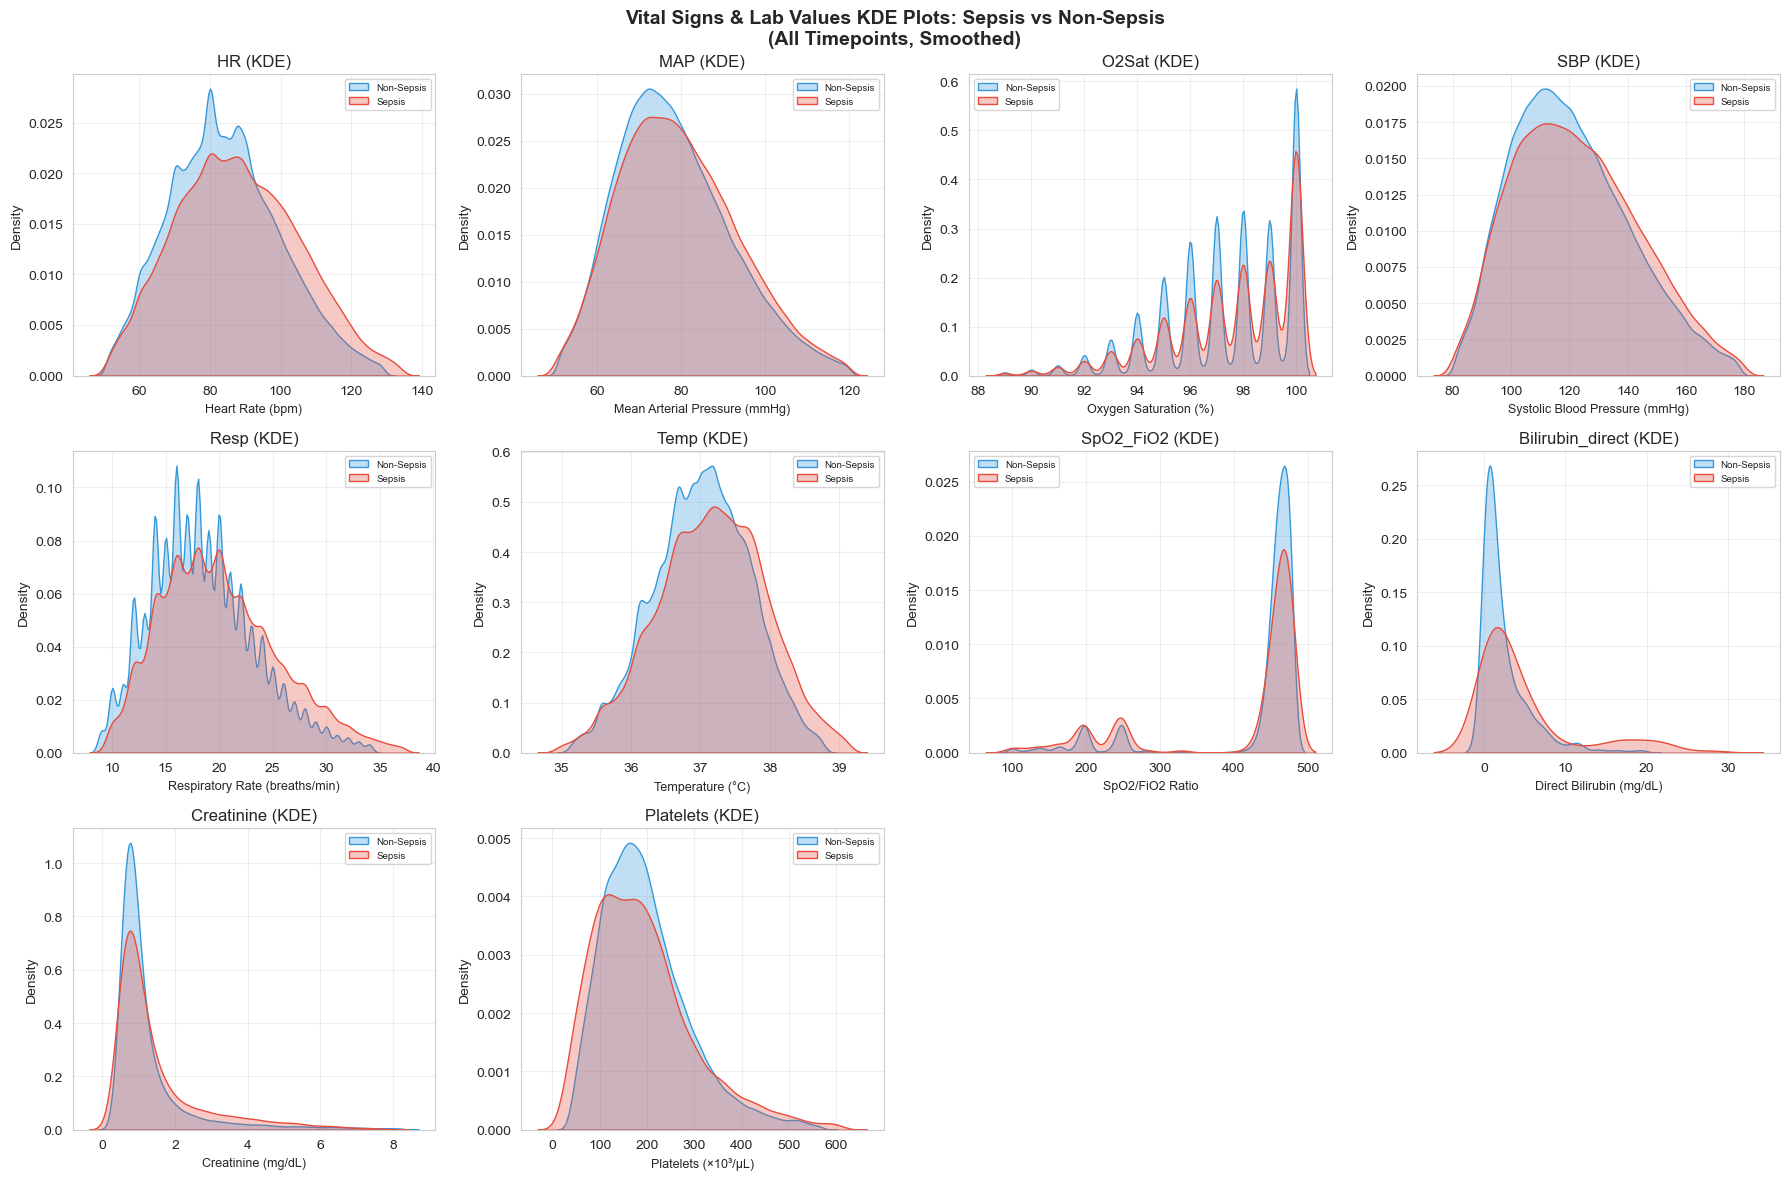

In [57]:
def plot_kde_comparison(combined_df):
    """
    Create KDE plots for smooth distribution comparison.
    """
    n_vitals = len(VITALS)
    n_cols = 4
    n_rows = (n_vitals + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()
    
    colors = {'Sepsis': '#e74c3c', 'Non-Sepsis': '#3498db'}
    
    for idx, vital in enumerate(VITALS):
        ax = axes[idx]
        
        sepsis_data = combined_df[combined_df['SepsisPatient'] == 'Sepsis'][vital].dropna()
        non_sepsis_data = combined_df[combined_df['SepsisPatient'] == 'Non-Sepsis'][vital].dropna()
        
        if len(sepsis_data) < 10 or len(non_sepsis_data) < 10:
            ax.text(0.5, 0.5, f'Insufficient data\nfor {vital}', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(vital)
            continue
        
        # Filter outliers
        sepsis_filtered = sepsis_data[(sepsis_data >= sepsis_data.quantile(0.01)) & 
                                       (sepsis_data <= sepsis_data.quantile(0.99))]
        non_sepsis_filtered = non_sepsis_data[(non_sepsis_data >= non_sepsis_data.quantile(0.01)) & 
                                               (non_sepsis_data <= non_sepsis_data.quantile(0.99))]
        
        sns.kdeplot(non_sepsis_filtered, ax=ax, color=colors['Non-Sepsis'], 
                    label='Non-Sepsis', fill=True, alpha=0.3)
        sns.kdeplot(sepsis_filtered, ax=ax, color=colors['Sepsis'], 
                    label='Sepsis', fill=True, alpha=0.3)
        
        ax.set_xlabel(VITAL_NAMES[vital], fontsize=9)
        ax.set_ylabel('Density')
        ax.set_title(f'{vital} (KDE)')
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)
    
    # Hide unused subplots
    for idx in range(len(VITALS), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Vital Signs & Lab Values KDE Plots: Sepsis vs Non-Sepsis\n(All Timepoints, Smoothed)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Plot KDE
plot_kde_comparison(combined_df)

## 9. Summary & Key Findings

### Typical patterns in Sepsis patients:

**Vital Signs:**
- **HR** ↑ Higher (tachycardia - body fighting infection)
- **MAP** ↓ Lower (hypotension - vasodilation from sepsis)
- **O2Sat** ↓ Lower (respiratory compromise)
- **SBP** ↓ Lower (septic shock)
- **Resp** ↑ Higher (tachypnea - compensating for metabolic acidosis)
- **Temp** ↑ Higher (fever - immune response to infection)
- **SpO2/FiO2** ↓ Lower (respiratory failure, SOFA respiratory score)

**Lab Values (SOFA Components):**
- **Bilirubin_direct** ↑ Higher (liver dysfunction, SOFA hepatic score)
- **Creatinine** ↑ Higher (kidney failure, SOFA renal score)
- **Platelets** ↓ Lower (coagulopathy/DIC, SOFA coagulation score)

In [58]:
# Final summary table
print("\n" + "="*60)
print("KEY DIFFERENCES: Sepsis vs Non-Sepsis")
print("="*60)

for _, row in stats_df.iterrows():
    direction = "↑" if row['Difference'] > 0 else "↓"
    print(f"\n{row['Vital']:8} | Sepsis patients have {direction} {abs(row['% Diff']):.1f}% {'higher' if row['Difference'] > 0 else 'lower'} {row['Vital']}")
    print(f"         | Non-Sepsis: {row['Non-Sepsis Mean']:.1f} ± {row['Non-Sepsis Std']:.1f}")
    print(f"         | Sepsis:     {row['Sepsis Mean']:.1f} ± {row['Sepsis Std']:.1f}")


KEY DIFFERENCES: Sepsis vs Non-Sepsis

HR       | Sepsis patients have ↑ 5.8% higher HR
         | Non-Sepsis: 84.1 ± 14.0
         | Sepsis:     89.0 ± 15.8

MAP      | Sepsis patients have ↓ 0.6% lower MAP
         | Non-Sepsis: 78.5 ± 10.8
         | Sepsis:     78.0 ± 10.8

O2Sat    | Sepsis patients have ↑ 0.2% higher O2Sat
         | Non-Sepsis: 97.2 ± 2.3
         | Sepsis:     97.3 ± 2.0

SBP      | Sepsis patients have ↓ 0.7% lower SBP
         | Non-Sepsis: 120.3 ± 16.4
         | Sepsis:     119.5 ± 16.9

Resp     | Sepsis patients have ↑ 8.8% higher Resp
         | Non-Sepsis: 18.5 ± 3.5
         | Sepsis:     20.1 ± 4.3

Temp     | Sepsis patients have ↑ 0.4% higher Temp
         | Non-Sepsis: 36.9 ± 0.5
         | Sepsis:     37.1 ± 0.7

SpO2_FiO2 | Sepsis patients have ↓ 7.4% lower SpO2_FiO2
         | Non-Sepsis: 429.3 ± 43.5
         | Sepsis:     397.5 ± 49.5

Bilirubin_direct | Sepsis patients have ↑ 73.1% higher Bilirubin_direct
         | Non-Sepsis: 2.4 ± 3.9
   